In [1]:
#Anthony Hernandez

In [2]:
import pandas as pd

In [3]:
Y_val=pd.read_csv("Compound.txt",skiprows=7,usecols=[2],sep="\t",header=None)#Class labels
#|||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
X_val=pd.read_csv("Compound.txt",skiprows=7,usecols=[0,1],sep="\t",header=None)# Values


In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold# used grid search to tune the SVM
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_val, Y_val, test_size=0.2, random_state=67
)

In [6]:
y_train=y_train.to_numpy().ravel() #making the class labels into 1D or else the svm will have problems training

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)#learns mean and standard deviation, then transforms the data based on that 
X_test_scaled = scaler.transform(X_test)# transforms data based on the learned mean and standard deviation from the training data so that they can
                                        # be scaled the same and overcome overfitting

In [8]:
#param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
#              'gamma':[0.0001, 0.001, 0.01, 1, 10, 100, 1000]}
#svm_rbf = SVC(kernel='rbf')
#grid_search = GridSearchCV(svm_rbf, 
#                           param_grid, 
#                          cv=3, 
#                          n_jobs=-1)
#grid_search.fit(X_train_scaled, y_train)
#print(
#    "Best parameters are {} \nScore : {}%".format(
#        grid_search.best_params_, grid_search.best_score_*100)
#)
#Code from geeksforgeeks used to optimize rbf param

In [9]:
svm_rbf= SVC(kernel= "rbf",C= 10, gamma= 1,class_weight="balanced")
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf=(svm_rbf.predict(X_test_scaled))

In [10]:
#svm = SVC(kernel='poly')

# 2. Define parameter grid (without 'svm__' prefixes)
#param_grid = {
#    'C': [0.1, 1, 10, 100],
#    'degree':[2, 3, 4],
#    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
#    'coef0': [0.0, 1.0, 2.0]
#}

# 3. Establish cross-validation
#cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Configure and run Grid Search
#grid_search = GridSearchCV(
#   estimator=svm,
#    param_grid=param_grid,
#    cv=cv_strategy,
#    scoring='accuracy',
#    n_jobs=-1,
#    verbose=1
#)

# Assuming X_train is scaled and y_train is a 1D array of discrete class labels
#grid_search.fit(X_train_scaled, y_train)

#print(f"Best Parameters: {grid_search.best_params_}")
#print(f"Best CV Score: {grid_search.best_score_:.4f}")
#similar to the geeks for geeks code but used to optimize poly kernel param

In [11]:
svm_poly= SVC(kernel= "poly",degree= 4, C= 10, gamma= 1, coef0= 1.0,class_weight="balanced")
svm_poly.fit(X_train_scaled, y_train)
y_pred_poly=(svm_poly.predict(X_test_scaled))

In [12]:
import numpy as np
from scipy.special import softmax
from sklearn.metrics import roc_auc_score, f1_score, classification_report

# 1. Get multi-class decision scores (shape: n_samples x n_classes)
scores_poly = svm_poly.decision_function(X_test_scaled)
scores_rbf = svm_rbf.decision_function(X_test_scaled)

# 2. Convert scores to pseudo-probabilities so rows sum to 1 (required by roc_auc_score)
probs_poly = softmax(scores_poly, axis=1)
probs_rbf = softmax(scores_rbf, axis=1)

print("Max score difference:", np.max(np.abs(scores_poly - scores_rbf)))
print("Poly Multi-class ROC-AUC (OVR):", roc_auc_score(y_test, probs_poly, multi_class="ovr"))
print("RBF Multi-class ROC-AUC (OVR):", roc_auc_score(y_test, probs_rbf, multi_class="ovr"))
print("Poly Macro F1:", f1_score(y_test, y_pred_poly, average="macro"))
print("RBF Macro F1:", f1_score(y_test, y_pred_rbf, average="macro"))
print("Support vectors per class (Poly vs RBF):", svm_poly.n_support_, "vs", svm_rbf.n_support_)


Max score difference: 3.1113650212365487
Poly Multi-class ROC-AUC (OVR): 0.9962526882542401
RBF Multi-class ROC-AUC (OVR): 0.9941297955397913
Poly Macro F1: 0.9821289821289821
RBF Macro F1: 0.9821289821289821
Support vectors per class (Poly vs RBF): [10  5  3  4 12  2] vs [19 12  7  8 27  6]


In [13]:
Y_val=Y_val.to_numpy().ravel()

In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 67)

pipe_poly = make_pipeline(
    StandardScaler(),
    SVC(kernel="poly", degree= 4, C= 10, gamma= 1, coef0= 1.0, class_weight="balanced")
)
pipe_rbf = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C= 10, gamma= 1, class_weight= "balanced")
)

cv_poly= cross_val_score(pipe_poly, X_val, Y_val, cv= cv, scoring= "f1_macro")
cv_rbf= cross_val_score(pipe_rbf, X_val, Y_val, cv= cv, scoring= "f1_macro")

print(f"Poly 5-Fold Macro F1: {cv_poly.mean():.4f} ± {cv_poly.std():.4f}")
print(f"RBF  5-Fold Macro F1: {cv_rbf.mean():.4f} ± {cv_rbf.std():.4f}")


Poly 5-Fold Macro F1: 0.9854 ± 0.0106
RBF  5-Fold Macro F1: 0.9894 ± 0.0053


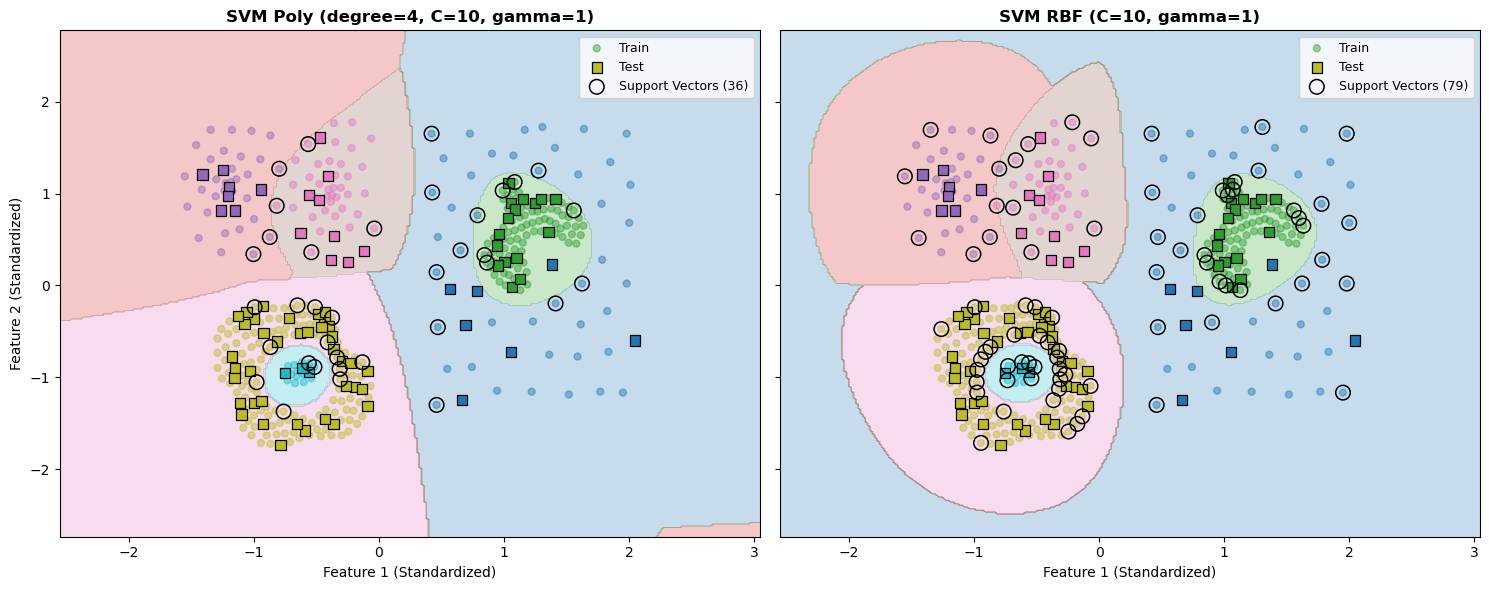

In [15]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

X_tr= np.asarray(X_train_scaled)
X_te= np.asarray(X_test_scaled)

models = [
    ("SVM Poly (degree=4, C=10, gamma=1)", svm_poly),
    ("SVM RBF (C=10, gamma=1)", svm_rbf),
]

fig, axes = plt.subplots(1, 2, figsize= (15, 6), sharex= True, sharey= True)
cmap= plt.cm.tab10  # Distinct colors for 6 classes

for ax, (title, model) in zip(axes, models):
    # 1. Shade the 6 predicted class regions across the 2D plane
    DecisionBoundaryDisplay.from_estimator(
        model,
        np.vstack([X_tr, X_te]),
        response_method="predict",
        cmap= cmap,
        alpha= 0.25,
        grid_resolution= 300,
        ax= ax,
    )

    # 2. Plot training points (faint circles) and test points (solid squares)
    ax.scatter(
        X_tr[:, 0], X_tr[:, 1],
        c= y_train, cmap= cmap, s= 25, alpha= 0.45, label= "Train"
    )
    scatter_test = ax.scatter(
        X_te[:, 0], X_te[:, 1],
        c= y_test, cmap= cmap, s= 55, marker= "s", edgecolors= "black", linewidth= 0.9, label= "Test"
    )

    # 3. Highlight support vectors with hollow black rings
    sv = model.support_vectors_
    ax.scatter(
        sv[:, 0], sv[:, 1],
        s= 110, facecolors= "none", edgecolors= "black", linewidth=1.1,
        label= f"Support Vectors ({len(sv)})"
    )

    ax.set_title(title, fontsize= 12, fontweight= "bold")
    ax.set_xlabel("Feature 1 (Standardized)")
    ax.legend(loc= "upper right", frameon= True, fontsize= 9)

axes[0].set_ylabel("Feature 2 (Standardized)")
plt.tight_layout()
plt.show()